# 🚀 Practice Day 51

**📅 Date:** **2026-11-03**  
**📁 Category:** **Phase 3 · 시각화 스토리텔링(Seaborn) (Round 4/5)**

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Use Seaborn to visually tell the story of what drives coffee bean price — altitude, growing region, and quality score
  (Seaborn으로 무엇이 원두 가격을 좌우하는지 — 고도·산지·품질점수 — 시각적으로 스토리텔링하기)
- Quantify how strongly altitude correlates with quality, how price differs across regions, and how quality relates to price
  (고도와 품질점수의 상관관계, 산지별 가격 차이, 품질점수와 가격의 관계를 정량적으로 파악하기)

---
# 📂 Dataset

**Dataset Name:** Highland Roasters — Coffee Bean Quality Data / Highland Roasters — 원두 품질 평가 데이터

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** 280 coffee bean lots (single table) across 6 growing regions (Ethiopia, Colombia, Guatemala, Kenya, Brazil, Vietnam). Includes growing altitude, a cupping (quality) score on a 0-100 scale, and price per kg in USD. Clean — no missing values or duplicates. Several variables jointly shape price, so the focus is on using Seaborn to visualize those relationships and build a narrative.
(6개 산지(Ethiopia/Colombia/Guatemala/Kenya/Brazil/Vietnam)의 원두 280개 로트 데이터입니다(단일 테이블). 재배 고도, 0~100점 척도의 커핑(품질) 점수, kg당 가격(USD)을 포함합니다. 결측치·중복 없이 깨끗합니다. 여러 변수가 함께 가격에 영향을 미치는 구조라, Seaborn으로 관계를 시각화하며 스토리를 풀어가는 데 초점을 둡니다.)

## Dataset Preview

In [52]:
# Dataset Preview
import pandas as pd
import numpy as np

np.random.seed(42)
rng = np.random.default_rng(42)

# --- Generate coffee bean quality data across 6 growing regions ---
n = 280
regions = ['Ethiopia', 'Colombia', 'Guatemala', 'Kenya', 'Brazil', 'Vietnam']
region_w = [0.16, 0.20, 0.14, 0.12, 0.24, 0.14]
region_altitude_base = {'Ethiopia': 1900, 'Colombia': 1650, 'Guatemala': 1550, 'Kenya': 1800, 'Brazil': 1100, 'Vietnam': 900}
region_price_premium = {'Ethiopia': 1.25, 'Colombia': 1.05, 'Guatemala': 1.0, 'Kenya': 1.2, 'Brazil': 0.75, 'Vietnam': 0.6}

region_choice = rng.choice(regions, size=n, p=region_w)
altitude = np.array([region_altitude_base[r] for r in region_choice]) + rng.normal(0, 150, n)
altitude = np.clip(altitude, 400, 2300).round().astype(int)

# cupping score (specialty-coffee quality score, 0-100 scale) driven mainly by altitude, plus noise
cupping_score = 74 + (altitude - 900) / 100 * 1.1 + rng.normal(0, 2.0, n)
cupping_score = np.clip(cupping_score, 60, 96).round(1)

# price driven by cupping score and a region premium (USD per kg)
base_price = 8 + (cupping_score - 74) * 0.9
price = base_price * np.array([region_price_premium[r] for r in region_choice]) * rng.normal(1.0, 0.06, n)
price = price.round(1)  # nearest $0.10

df = pd.DataFrame({
    'bean_id': [f'B{str(i+1).zfill(4)}' for i in range(n)],
    'region': region_choice,
    'altitude_m': altitude,
    'cupping_score': cupping_score,
    'price_per_kg': price
})

df.head(10)


,bean_id,region,altitude_m,cupping_score,price_per_kg
0,B0001,Brazil,1147,77.8,9.4
1,B0002,Guatemala,1535,81.6,13.8
2,B0003,Brazil,1414,83.7,12.3
3,B0004,Brazil,1336,78.6,8.7
4,B0005,Ethiopia,1958,85.0,21.2
5,B0006,Vietnam,786,71.2,3.2
6,B0007,Brazil,933,72.3,5.3
7,B0008,Brazil,1279,75.7,7.9
8,B0009,Ethiopia,1939,83.7,20.5
9,B0010,Guatemala,1622,81.8,16.7


## Dataset Information

In [53]:
# Dataset Information
df.info()
print("\nShape:", df.shape)
df.describe(include='all')


<class 'pandas.DataFrame'>
RangeIndex: 280 entries, 0 to 279
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   bean_id        280 non-null    str    
 1   region         280 non-null    str    
 2   altitude_m     280 non-null    int64  
 3   cupping_score  280 non-null    float64
 4   price_per_kg   280 non-null    float64
dtypes: float64(2), int64(1), str(2)
memory usage: 11.1 KB

Shape: (280, 5)


,bean_id,region,altitude_m,cupping_score,price_per_kg
count,280,280,280.000000,280.000000,280.000000
unique,280,6,NaN,NaN,NaN
top,B0001,Brazil,NaN,NaN,NaN
freq,1,73,NaN,NaN,NaN
mean,NaN,NaN,1471.410714,80.124286,13.884286
std,NaN,NaN,377.968773,4.810538,6.755205
min,NaN,NaN,515.000000,68.000000,1.600000
25%,NaN,NaN,1123.750000,76.200000,7.200000
50%,NaN,NaN,1537.500000,80.900000,14.750000
75%,NaN,NaN,1784.000000,83.725000,19.300000


---
# ❓ Business Questions

1. **(Analysis)** How strong is the correlation between growing altitude and cupping score?
   (재배 고도와 커핑 점수의 상관관계는 얼마나 강한가?)
2. **(Analysis)** How does average price per kg differ across the six growing regions?
   (산지별 평균 가격은 어떻게 다른가?)
3. **(Analysis)** How strong is the correlation between cupping score and price?
   (커핑 점수와 가격의 상관관계는 얼마나 강한가?)
4. **(Visualization)** Show the relationship between altitude and cupping score, broken out by region.
   (고도와 커핑 점수의 관계를 산지별로 나누어 보면?)
5. **(Visualization)** Show how the price distribution itself differs across regions.
   (산지별 가격 분포 자체는 어떻게 다른가?)

---
# 🔍 Data Cleaning Check


In [54]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("Missing values")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDtypes")
print(df.dtypes)

print("\nColumn names")
print(df.columns.tolist())

obj_cols = df.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(df[obj_cols].nunique())


Missing values
bean_id          0
region           0
altitude_m       0
cupping_score    0
price_per_kg     0
dtype: int64

Duplicate rows: 0

Dtypes
bean_id              str
region               str
altitude_m         int64
cupping_score    float64
price_per_kg     float64
dtype: object

Column names
['bean_id', 'region', 'altitude_m', 'cupping_score', 'price_per_kg']

Text columns — unique counts
bean_id    280
region       6
dtype: int64


---
# 📊 Analysis

## Question 1

**Question:** How strong is the correlation between growing altitude and cupping score? (고도와 커핑 점수의 상관관계는?)

**Result:** The correlation between altitude and cupping score is **0.908**.  
(고도와 커핑 점수의 상관은 0.908)

**Insight:** The relationship is positive. Higher altitude goes with a higher cupping score.  
(관계는 양이다. 고도가 높을수록 커핑 점수도 높다)

In [55]:
# Question 1: correlation between altitude_m and cupping_score
df['altitude_m'].corr(df['cupping_score'])

np.float64(0.9081147422822974)

<Axes: xlabel='altitude_m', ylabel='cupping_score'>

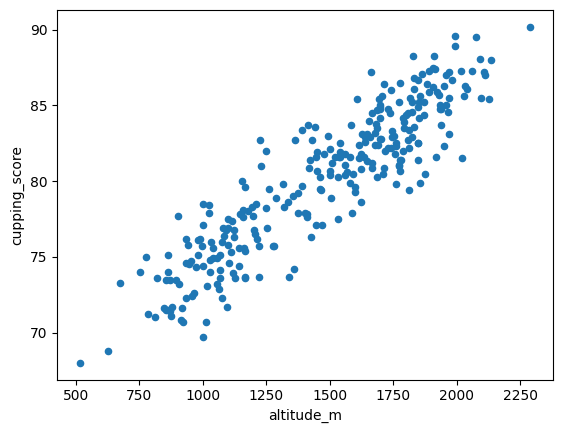

In [56]:
df.plot.scatter(x='altitude_m', y='cupping_score')

## Question 2

**Question:** How does average price per kg differ across the six growing regions? (산지별 평균 가격은?)

**Result:** Ethiopia has the highest average price at **$22.23**. Vietnam has the lowest at **$4.85**. The gap is **$17.39**.  
(평균 가격 1위는 Ethiopia $22.23, 맨 아래는 Vietnam $4.85. 차이는 $17.39)

**Insight:** Kenya is next at **$19.39**, which is **$2.85** below Ethiopia. Colombia averages **$16.84**, Guatemala **$14.23**, and Brazil **$7.26**.  
(다음은 Kenya $19.39로 Ethiopia보다 $2.85 적음. Colombia $16.84, Guatemala $14.23, Brazil $7.26)

In [57]:
# Question 2: average price by region
df.groupby('region')['price_per_kg'].mean().sort_values(ascending=False)

region
Ethiopia     22.232075
Kenya        19.386667
Colombia     16.841176
Guatemala    14.234146
Brazil        7.261644
Vietnam       4.846875
Name: price_per_kg, dtype: float64

## Question 3

**Question:** How strong is the correlation between cupping score and price? (커핑 점수와 가격의 상관관계는?)

**Result:** The correlation between cupping score and price is **0.951**.  
(커핑 점수와 가격의 상관은 0.951)

**Insight:** That is **0.043** above the altitude–score correlation of **0.908**.  
(고도–점수 상관 0.908보다 0.043 높음)

In [58]:
# Question 3: correlation between cupping_score and price_per_kg
df['cupping_score'].corr(df['price_per_kg'])

np.float64(0.9511942128229053)

<Axes: xlabel='cupping_score', ylabel='price_per_kg'>

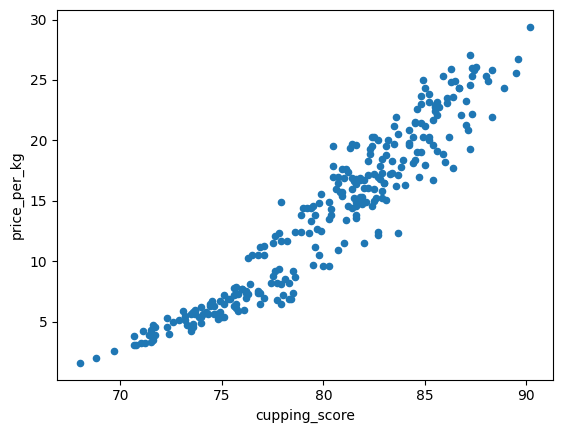

In [59]:
df.plot.scatter(x='cupping_score', y='price_per_kg')

---
# 📈 Visualization

**Chart 1:** Scatter plot with regression line (Seaborn) — altitude vs cupping score, colored by region (Seaborn 산점도+회귀선: 고도 vs 커핑 점수, 산지별 색상 구분)

*Interpretation:* One line rises across all regions. The altitude–score correlation is **0.908**.  
(선은 모든 산지에 걸쳐 위로 향함. 고도–점수 상관은 0.908)

---

**Chart 2:** Box plot or violin plot (Seaborn) — price distribution by region (Seaborn 박스플롯/바이올린플롯: 산지별 가격 분포)

*Interpretation:* The regions follow the average-price table, from Ethiopia at **$22.23** to Vietnam at **$4.85**.  
(산지 순서는 평균 가격 표와 같음. Ethiopia $22.23에서 Vietnam $4.85까지)

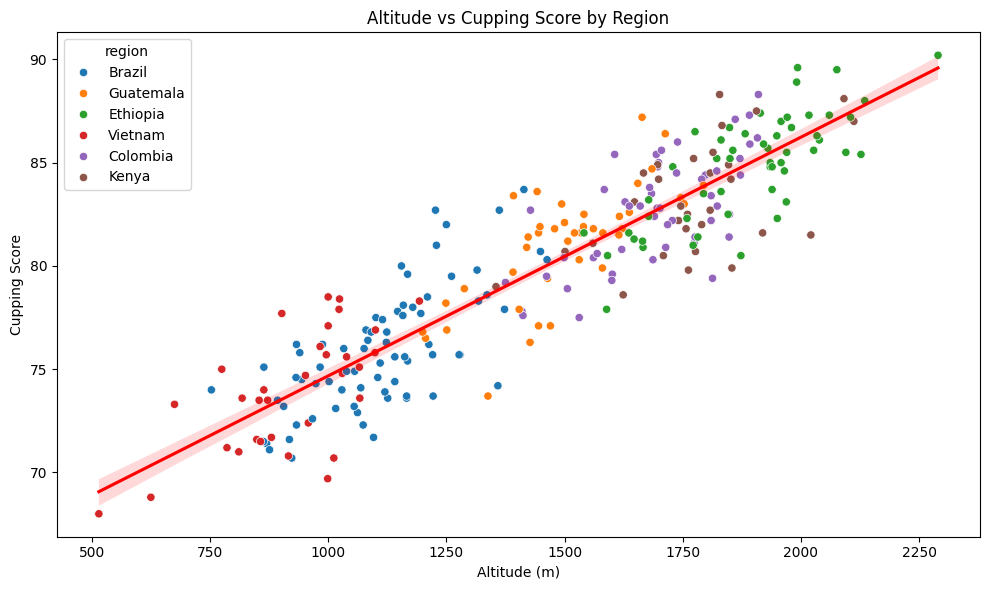

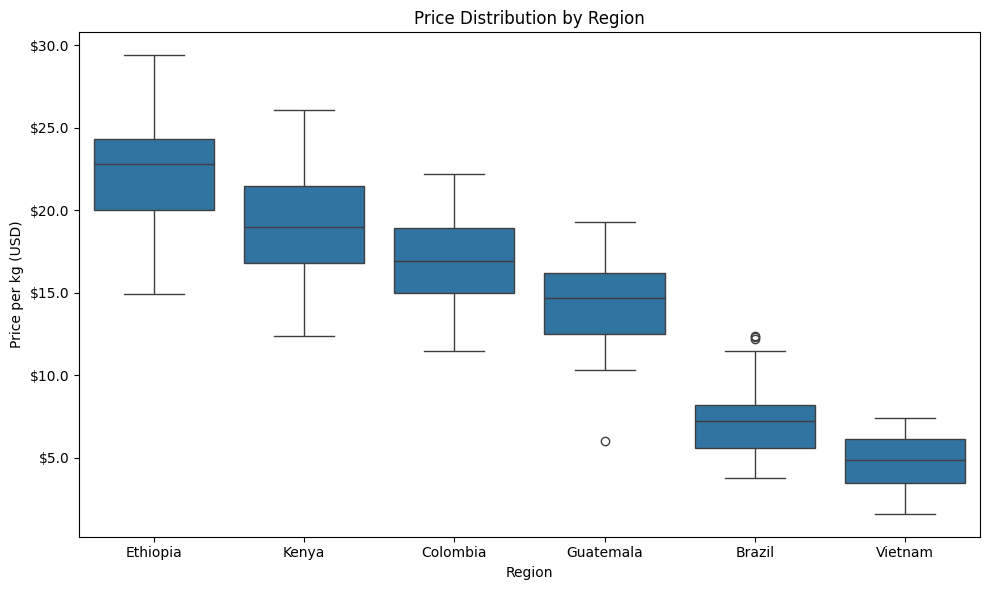

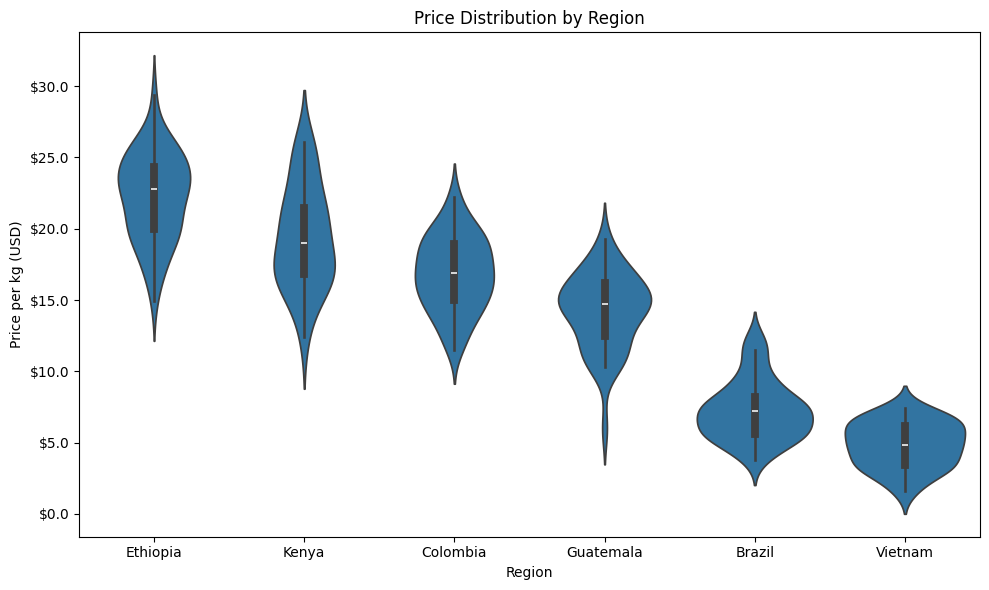

In [60]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Chart 1: altitude vs cupping score scatter + regression line, colored by region
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(x='altitude_m', y='cupping_score', data=df, hue='region', ax=ax)
sns.regplot(x='altitude_m', y='cupping_score', data=df, scatter=False, line_kws={'color': 'red'}, ax=ax)
ax.set_title('Altitude vs Cupping Score by Region')
ax.set_xlabel('Altitude (m)')
ax.set_ylabel('Cupping Score')
plt.tight_layout()
plt.show()

# Chart 2: price distribution by region
region_order = df.groupby('region')['price_per_kg'].mean().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(x='region', y='price_per_kg', data=df, order=region_order, ax=ax)
ax.set_title('Price Distribution by Region')
ax.set_xlabel('Region')
ax.set_ylabel('Price per kg (USD)')
ax.yaxis.set_major_formatter('${x:,.1f}')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 6))
sns.violinplot(x='region', y='price_per_kg', data=df, order=region_order, ax=ax)
ax.set_title('Price Distribution by Region')
ax.set_xlabel('Region')
ax.set_ylabel('Price per kg (USD)')
ax.yaxis.set_major_formatter('${x:,.1f}')
plt.tight_layout()
plt.show()

---
# 💼 Business Insights
*What did I discover?*

- Altitude and cupping score move together. The correlation is **0.908**.  
  (고도와 커핑 점수는 같이 움직임. 상관은 0.908)
- Ethiopia averages **$22.23** per kg. Vietnam averages **$4.85**.  
  (Ethiopia 평균은 kg당 $22.23. Vietnam 평균은 $4.85)
- Cupping score and price move together more closely. The correlation is **0.951**.  
  (커핑 점수와 가격이 더 가깝게 움직임. 상관은 0.951)  

---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. The Ethiopia average of **$22.23** is **$17.39** above Vietnam at **$4.85**.  
   (Ethiopia 평균 $22.23은 Vietnam $4.85보다 $17.39 높음)
2. Price follows cupping score. Their correlation is **0.951**.  
   (가격은 커핑 점수를 따라감. 상관은 0.951)
3. Altitude and cupping score also rise together, at **0.908**.  
   (고도와 커핑 점수도 같이 올라감. 상관은 0.908)  

---
# ❌ Mistakes
*What mistakes did I make today?*

- The price charts listed regions in data order. The average-price table runs from Ethiopia to Vietnam.  
  (가격 차트는 산지를 데이터 순서로 두었음. 평균 가격 표는 Ethiopia에서 Vietnam 순서)  

---
# ✅ What I Learned
*Today's biggest lesson*

- `.corr()` measures the altitude–score link and the score–price link.  
  (`.corr()`로 고도–점수, 점수–가격 관계를 잰다)
- `groupby('region')['price_per_kg'].mean().sort_values(ascending=False)` ranks the six regions.  
  (`groupby('region')['price_per_kg'].mean().sort_values(ascending=False)`가 여섯 산지 순위를 만듦)
- `sns.scatterplot` colors the points by region, and one `sns.regplot` line fits all of the points.  
  (`sns.scatterplot`은 점을 산지 색으로 나누고, `sns.regplot` 선 하나가 점 전체에 맞춰짐)  

---
# 🧠 Reflection

**What was difficult?**  
Reading the red line on the region-colored scatter.  
(산지 색 산점도 위의 빨간 선을 읽는 것)

**Why?**  
The colors split the points by region. The line is one fit for every lot.  
(색은 점을 산지별로 나눔. 선은 로트 전체에 맞춘 하나)

**How did I solve it?**  
Drew the points with `hue='region'` and the line with `sns.regplot(..., scatter=False)`.  
(점은 `hue='region'`으로, 선은 `sns.regplot(..., scatter=False)`로 그림)

**What would I do differently next time?**  
Set the region axis to the sorted average-price order before reading the boxes.  
(박스를 읽기 전에 산지 축을 평균 가격 정렬 순서로 맞추기)

---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★★☆☆  
Altitude and cupping score correlate at **0.908**. Ethiopia averages **$22.23**, and cupping score correlates with price at **0.951**.  
(고도와 커핑 점수 상관은 0.908. Ethiopia 평균은 $22.23, 커핑 점수와 가격 상관은 0.951)

**Confidence**  
★★★★★★☆☆☆☆  

**Difficulty**  
★★★★☆☆☆☆☆☆  
The two correlations and the region averages were direct. The hard part was the single regression line.  
(상관 두 개와 산지 평균은 바로 나왔음. 어려운 부분은 회귀선 하나였음)

---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Practice Day 53 — SQL window functions (Round 4/5)  
  (SQL 윈도우 함수로 행 사이 순위와 누적을 구하기)  